# Metrics

In [1]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.append('../src')

# The heatmaps have colorbar axes that tight_layout cannot handle; the layout is fine.
warnings.filterwarnings('ignore', message='This figure includes Axes that are not compatible with tight_layout')

from viz.utils import savefig, set_mpl_style, ylabel_annot, subplot_title
set_mpl_style()
from pipeline.collect_metrics import load_bird_metrics, with_rhythm_types
from viz.heatmap import per_column_heatmap, cmap_slice
from constants import DATASETS, RHYTHM_TYPES

In [2]:
# Common index levels
by_cond = ['dataset_id', 'rhythm_type', 'label_type']

# Per-bird values (for colour ranges) and their condition means (see metrics.condition)
birds = load_bird_metrics()
metrics = pd.read_csv('../data/metrics.csv', index_col=by_cond)

## Column config

In [3]:
def quantile_vrange(values, quantile=0.01):
    vmin, vmax = np.nanquantile(values, [quantile, 1 - quantile]).round()
    return dict(vmin=vmin, vmax=vmax)

In [4]:
# Column configurations

raw_config = [
    dict(name='n_labels', label='Labels', round=1, **quantile_vrange(birds['n_labels'])),
    dict(name='units_per_label', label='Units / label', round=0, **quantile_vrange(birds['units_per_label'])),
    dict(name='dur_mean', label='Duration', round=0, **quantile_vrange(birds['dur_mean'])),
    dict(name='inconsistency', label='Inconsistency', round=1, **quantile_vrange(birds['inconsistency'])),
    dict(name='isolated_label', label='Differentiation', unit='%'),
    dict(name='n_isolated_labels', label='Isolated\nlabels', round=1, **quantile_vrange(birds['n_isolated_labels'])),
    dict(name='cluster_inconsistency', label='Duration SD\nper cluster (ms)', round=1, **quantile_vrange(birds['cluster_inconsistency'])),
    dict(name='isolated_cluster', label='Birds with ≥1\nisolated\ncluster (%)', unit='%'),
    dict(name='repetitions', label='Repetitions', unit='%'),

    # Isochrony of each bird's frequent patterns, |r - 0.5| in [0, 0.5]
    dict(name='most_isochronous', label='Most\nisochronous', round=2, vmin=0, vmax=0.5),
    dict(name='median_isochrony', label='Median\nisochrony', round=2, vmin=0, vmax=0.5),
    dict(name='least_isochronous', label='Least\nisochronous', round=2, vmin=0, vmax=0.5),

    # Label-free isochrony of single dyads
    dict(name='non_isochrony', label='Non-isochrony', round=2, vmin=0, vmax=0.5),
    dict(name='perc_rel_isochronous', label='Rel. 1:1-share', unit='%'),
    dict(name='rho50', label='ρ$_\\mathbf{50}$', round=2, vmin=0, vmax=0.5),
    dict(name='asymmetry', label='Asym. (ms)', round=0, **quantile_vrange(metrics['asymmetry'])),
    dict(name='perc_abs_isochronous', label='Abs. 1:1-share', unit='%'),
    dict(name='tau50', label='τ$_\\mathbf{50}$ (ms)', round=0, **quantile_vrange(metrics['tau50'])),
]

def set_config_defaults(config, metrics, add_units=False):
    for col in config:
        assert 'name' in col
        if 'label' not in col:
            col['label'] = col['name']

        if col.get("unit", None) == "%":
            col['vmin'] = col.get('vmin', 0)
            col['vmax'] = col.get('vmax', 100)
            col['round'] = col.get('round', 0)
        elif col.get("unit", None) == '1':
            col['vmin'] = col.get('vmin', 0)
            col['vmax'] = col.get('vmax', 1)
            col['round'] = col.get('round', 2)
            col['unit'] = None
        elif col.get("unit", None) == 'ms':
            col['round'] = col.get('round', 0)

        # Defaults
        col['fmt'] = col.get('fmt', f".{col.get('round', 2)}f")
        col['vmin'] = col.get('vmin', np.floor(metrics[col['name']].min()))
        col['vmax'] = col.get('vmax', np.ceil(metrics[col['name']].max()))

        if col.get('unit', False) and add_units:
            col['label'] = f"{col['label']} ({col['unit']})"
        
    config = {c['name']: c for c in config}
    for k in config.keys():
        del config[k]['name']
    return config

config = set_config_defaults(raw_config, metrics)

## Plotting functions

In [5]:
def align_top_level(df: pd.DataFrame) -> pd.DataFrame:
    """Reindex df so every value of the top index level has a row for every
    combination of the remaining levels seen anywhere in df, filling any
    gaps with NaN rows.
    """
    top_values = df.index.get_level_values(0).unique()
    rest = df.index.droplevel(0).unique()
    rest_tuples = rest if isinstance(rest, pd.MultiIndex) else [(v,) for v in rest]
    rest_names = list(rest.names) if isinstance(rest, pd.MultiIndex) else [rest.name]

    full_index = pd.MultiIndex.from_tuples(
        [(top, *r) for top in top_values for r in rest_tuples],
        names=[df.index.names[0], *rest_names],
    )
    return df.reindex(full_index)

UNIT_TYPE_LABELS = dict(ioi='IOIs', dur='durations', bound='boundaries')

def reshape_metrics(metrics, columns, datasets=['bvs', 'ns', 'rt', 'bwps-clean', 'bwps'], header_col='condition'):
    return (
        align_top_level(
            with_rhythm_types(metrics, by_cond)
                .assign(unit_type_label=lambda df: df['unit_type'].map(UNIT_TYPE_LABELS))
                .sort_values(['dataset_id', 'order'])[columns + [header_col]]
        )
            .reset_index()
            .drop(columns=['rhythm_type'])
            .set_index(['dataset_id', 'label_type', header_col])
            .loc[datasets]
    )

In [6]:
def draw_inset_outline(inset_ax, px=0.005, py=0.01, **kws):
    # get_tightbbox needs a render pass first so it reflects final (post-tight_layout) text positions/sizes.
    fig = plt.gcf()
    fig.canvas.draw()
    bbox = inset_ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.transFigure.inverted())

    rect_kws = dict(edgecolor='black', facecolor='white', linewidth=0.5, clip_on=False, zorder=0)
    rect_kws.update(**kws)
    inset_ax.add_artist(plt.Rectangle(
        (bbox.x0 - px, bbox.y0 - py),
        bbox.width + 2 * px,
        bbox.height + 2 * py,
        transform=fig.transFigure,
        **rect_kws
    ))

def draw_inset_heatmap(
        df, ax, 
        x0=0, 
        y0=.30,
        height=.2, 
        tick_width=.15,
        px=0.005, py=0.01, 
        yticklabels=None,
        **heatmap_kws
    ):
    # x, y, width, height
    inset_ax = ax.inset_axes([x0 + tick_width - px, y0 - 2*py, 1 - tick_width, height])
    kws = dict(
        column_title_pad=0.05,
        column_title_kws=dict(fontweight='normal', fontsize=7),
        cbar=False
    )
    kws.update(**heatmap_kws)
    per_column_heatmap(df, ax=inset_ax, **kws)

    inset_ax.set_xticks([])
    if yticklabels:
        inset_ax.set_yticks(np.arange(len(yticklabels)) + 0.5)
        inset_ax.set_yticklabels(yticklabels, ha='left', fontweight='bold', x=-1*tick_width, fontsize=7)
    return inset_ax

In [7]:
def plot_heatmaps(df, config, n_birds, label_type='annot', inset_kws={}, figsize=None, label_free=False, **kws):
    """Panels A/B (bvs, ns) use `label_type`; inset C (bwps, bwps-clean, rt) has no
    annotations, so it uses the predicted labels (or shuffled, if `label_type` is).
    Label-free metrics (label_type 'all') are used as they are. With
    ``label_free``, the inset title doesn't name a label type.
    """
    inset_label_type = label_type if label_type in ('shuffle', 'all') else 'pred'
    figsize = figsize or (3 + len(df.columns) * 1.25, 5.2)
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=figsize, sharey=True)
    heatmap_kws = dict(
        columns=config,
        cmap=cmap_slice('plasma', 0, 0.75),
        cbar_xpad=.05,
        cbar_location="bottom",
        column_title=True,
        column_title_kws=dict(fontsize=7),
        cbar_height=.03,
        text_kws=dict(fontsize=7.5)
    )
    heatmap_kws.update(**kws)
    per_column_heatmap(df.loc['bvs', label_type, :], ax=ax0, **heatmap_kws)
    per_column_heatmap(df.loc['ns', label_type, :], ax=ax1, **heatmap_kws)

    title_kws = dict(x=0, y=1.12, ha='left', fontweight='bold', fontsize=10)
    ax0.set_title(f"A. Burchardt, Varkevisser & Spierings (2025; $n={n_birds['bvs']}$)", **title_kws)
    ax1.set_title(f"B. Norton & Scharff (2016; $n = {n_birds['ns']}$)", **title_kws)

    ax0.axhline(6, c='w', lw=5)
    ax1.axhline(6, c='w', lw=5)
    ax0.axhline(3, c='w', lw=5)
    ax1.axhline(3, c='w', lw=5)
    yticks = [UNIT_TYPE_LABELS[RHYTHM_TYPES[r]['unit_type']] for r in DATASETS['bvs']['rhythm_types']]
    ax1.set_yticklabels(yticks)

    ## Inset table
    plt.tight_layout()

    # Unit level labels, centred on their rows (rows are heatmap y units)
    to_fig = fig.transFigure.inverted()
    for level, (start, stop) in dict(Syllable=(0, 3), Elements=(3, 6), Gaps=(6, 8)).items():
        _, y = to_fig.transform(ax0.transData.transform((0, (start + stop) / 2)))
        ylabel_annot(level, y=y)
    kws = dict(
        columns=heatmap_kws['columns'], cmap=heatmap_kws['cmap'], column_title=True,
        y0=.29, height=.21, tick_width=.2, text_kws=dict(fontsize=7),
        column_title_kws=dict(fontweight='normal', fontsize=6),
    )
    kws.update(**inset_kws)
    inset_ax = draw_inset_heatmap(
        df.loc[['bwps-clean', 'bwps', 'rt'], inset_label_type, :].dropna(how='all'), 
        yticklabels=[
            f"Bertolo\nclean ($n={n_birds['bwps-clean']}$)",
            f"Bertolo\nraw ($n={n_birds['bwps']}$)",
            f"Roeske\n($n={n_birds['rt']}$)",
        ],
        ax=ax1, **kws
    )
    inset_title = 'C. Other syllable IOI datasets'
    if not label_free:
        inset_title += {'shuffle': ' (shuffled labels)', 'pred': ' (predicted labels)'}.get(inset_label_type, '')
    inset_ax.set_title(inset_title, x=0, ha='left', fontweight='bold', y=1, pad=22)
    draw_inset_outline(inset_ax)
    return ax0, ax1, inset_ax

## Supplementary metrics table

In [8]:
# Number of birds per dataset (same across label types: annot/pred/shuffle relabel the
# same physical birds), used in the panel/row titles below
n_birds = birds.reset_index().groupby('dataset_id')['bird_id'].nunique()

In [9]:
desc_columns = [
    "n_labels",
    "units_per_label",
    "dur_mean",
    "inconsistency",
    "isolated_label",
    "repetitions",
]
iso_columns = [
    "non_isochrony",
    "perc_rel_isochronous",
    "rho50",
    "asymmetry",
    "perc_abs_isochronous",
    "tau50",
]
table_columns = desc_columns + iso_columns
table_config = {c: dict(config[c]) for c in table_columns}
table_metrics = reshape_metrics(metrics, table_columns, header_col='unit_type_label')

In [10]:
tables = {
    'descriptive': (desc_columns, cmap_slice('plasma', 0, .75)),
    'isochrony': (iso_columns, cmap_slice('viridis', 0, .75)),
}

def suppl_table(name, label_type, save=True):
    columns, cmap = tables[name]
    label_free = name == 'isochrony'
    plot_heatmaps(table_metrics[columns], table_config, n_birds, label_type=label_type, cmap=cmap, label_free=label_free)
    if not save:
        return
    if label_free:
        savefig(f'figS5-{name}')
    else:
        panel = 'abc'[['annot', 'pred', 'shuffle'].index(label_type)]
        savefig(f'figS4{panel}-{name}-{label_type}')

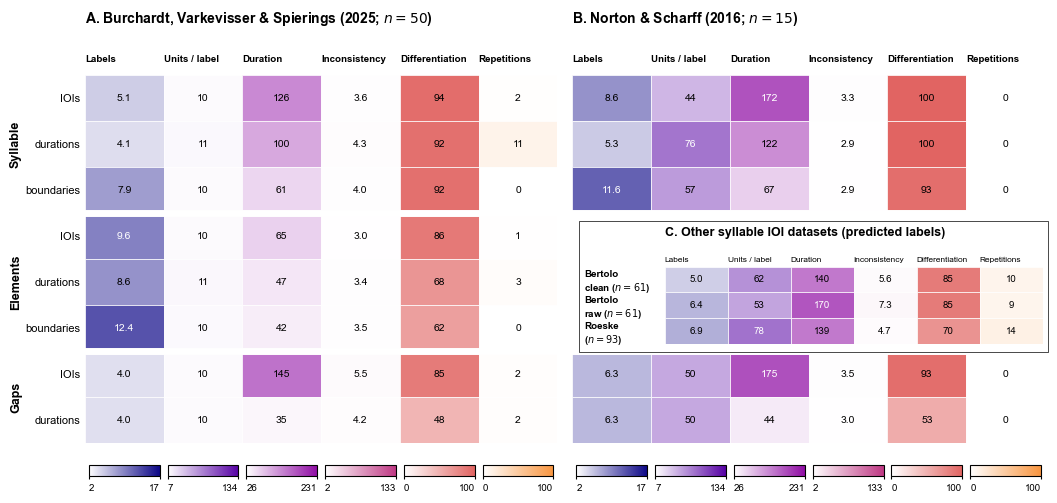

In [11]:
suppl_table('descriptive', 'annot')

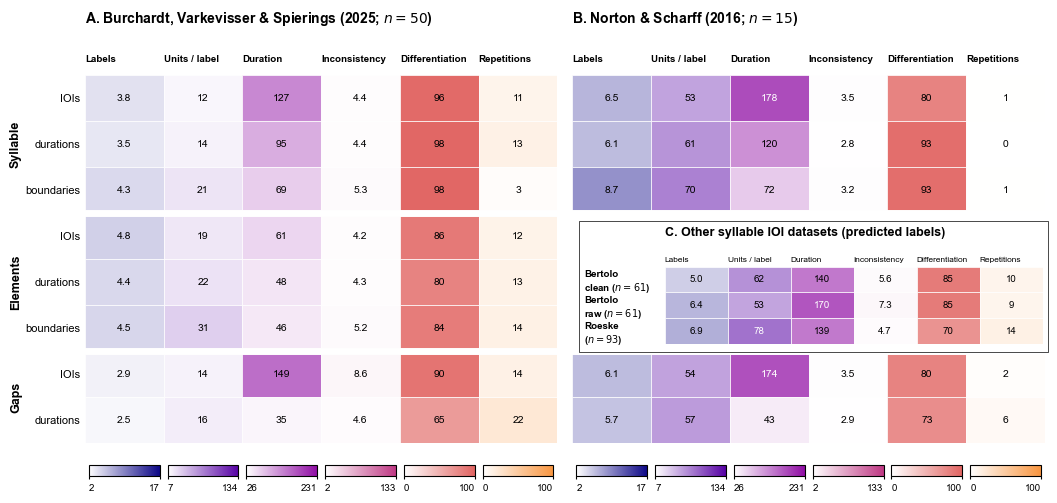

In [12]:
suppl_table('descriptive', 'pred')

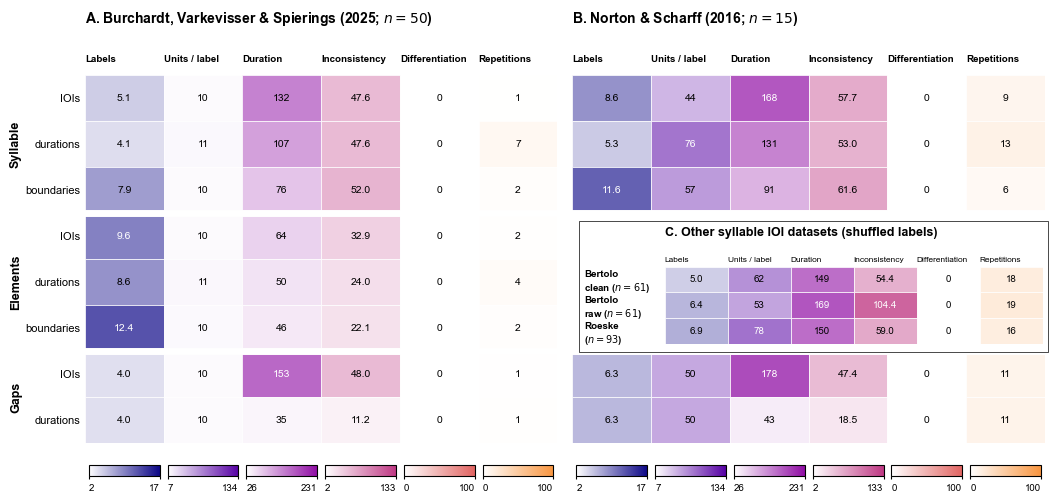

In [13]:
suppl_table('descriptive', 'shuffle')

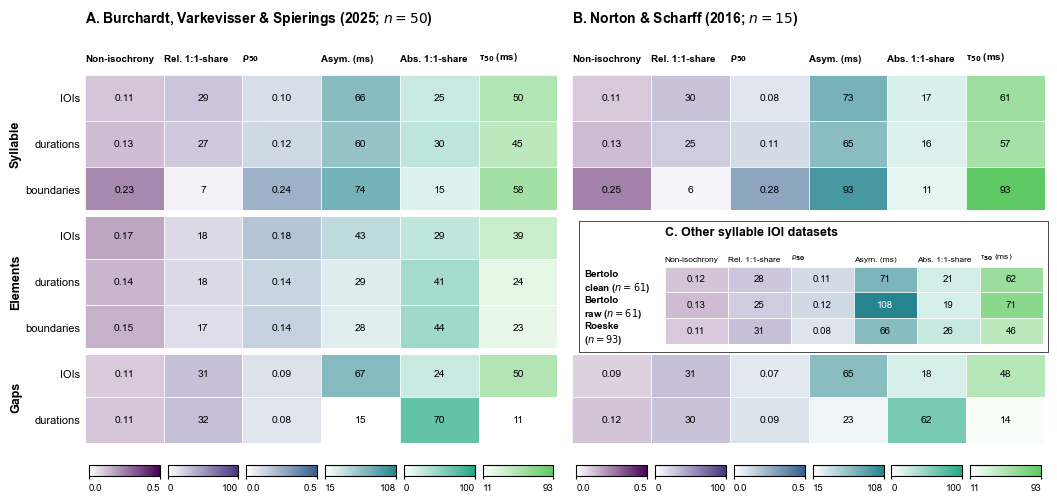

In [14]:
suppl_table('isochrony', 'annot')

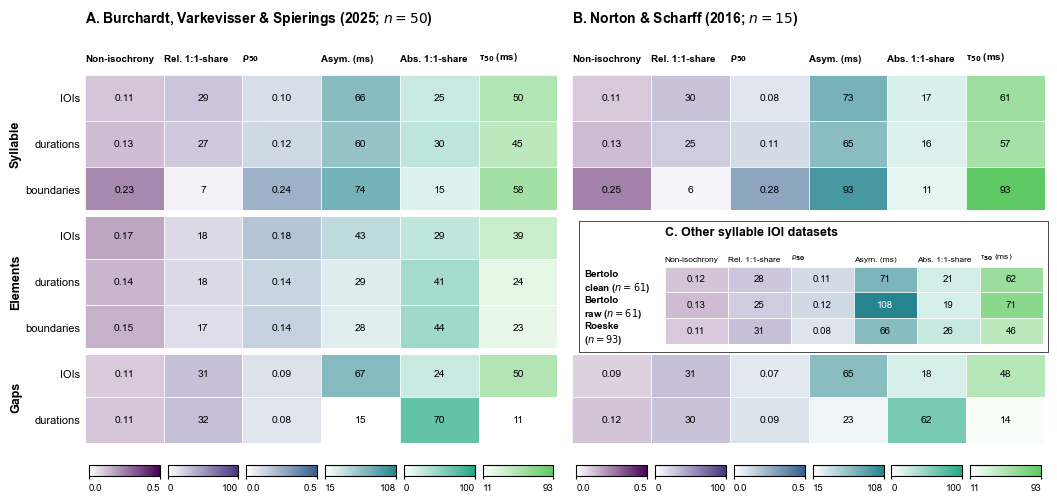

In [15]:
# Label-free: the same values as with annotated labels, so not saved
suppl_table('isochrony', 'pred', save=False)

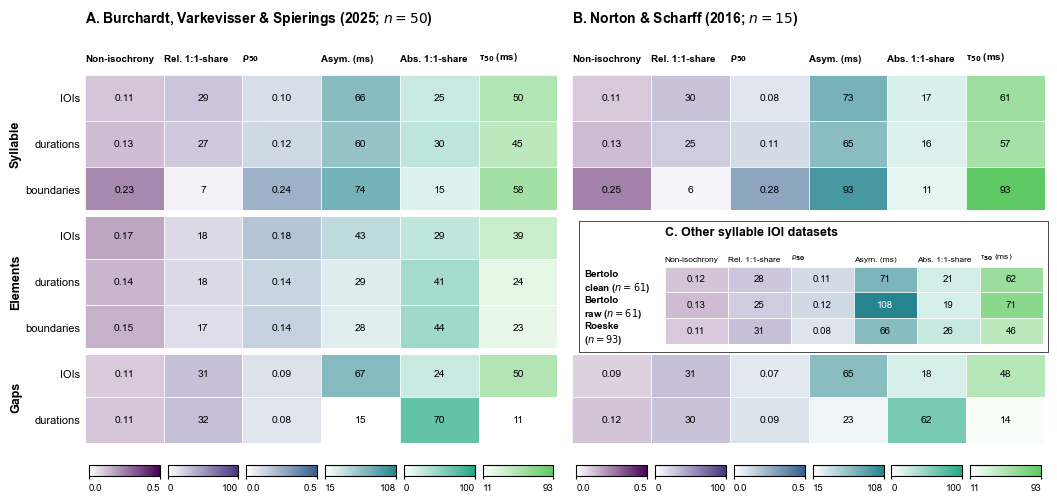

In [16]:
# Label-free: the same values as with annotated labels, so not saved
suppl_table('isochrony', 'shuffle', save=False)

## Long table with all metrics (redundant)

In [17]:
suppl_datasets = {
    "bvs": "Burchardt, Varkevisser & Spierings (2025)",
    "ns": "Norton & Scharff (2016)",
    "rt": 'Roeske et al. (2020)',
    "bwps-clean": "Bertolo et al. (2026, clean)",
    "bwps": "Bertolo et al. (2026, not cleaned)"
}

def big_suppl_table(metrics, config, columns=None, exclude_cols=[], label_type='annot', datasets=suppl_datasets):
    if columns is None:
        columns = list(config.keys())
    columns = [c for c in columns if c not in exclude_cols]
    all_metrics = reshape_metrics(metrics, columns).dropna(how='all')
    cond_counts = all_metrics.reset_index()['dataset_id'].value_counts()
    fig, axs = plt.subplots(
        len(datasets), 1, 
        height_ratios=[1 + cond_counts[id] for id in datasets],
        figsize=(4 + all_metrics.shape[1] * .5, 4 + sum(cond_counts) * .2),
        gridspec_kw=dict(hspace=0.25)
    )

    heatmap_kws = dict(
        columns=config,
        cmap=cmap_slice('gnuplot2', 0.1, .8),
        column_title_pad=.1,
        cbar_xpad=.05,
        cbar_height=0.4,
        cbar_location="bottom",
        column_title_rotation=45,
    )

    for i, (ax, dataset_id) in enumerate(zip(axs, datasets)):
        label_type_here = label_type if dataset_id in ['bvs', 'ns'] else 'pred'
        per_column_heatmap(
            all_metrics.loc[dataset_id, label_type_here, :],
            cbar=i == len(datasets)-1,
            column_title=i == 0,
            **heatmap_kws,
            ax=ax
        )
        if i > 0:
            ax.set_xticks([])

        if dataset_id in ['bvs', 'ns']:
            ax.axhline(3, c='w', lw=3)
            ax.axhline(3, c='.7', lw=.5)
        if dataset_id == 'bvs':
            ax.axhline(6, c='w', lw=3)
            ax.axhline(6, c='.7', lw=.5)

        subplot_title(i, datasets[dataset_id], ax=ax, fontsize=9)

    plt.annotate(
        "Mean across birds of per-bird values", 
        xy=(.95, .03), xycoords="subfigure fraction", 
        ha='right', va='bottom', fontsize=7, color='.5'
    )
    plt.tight_layout()

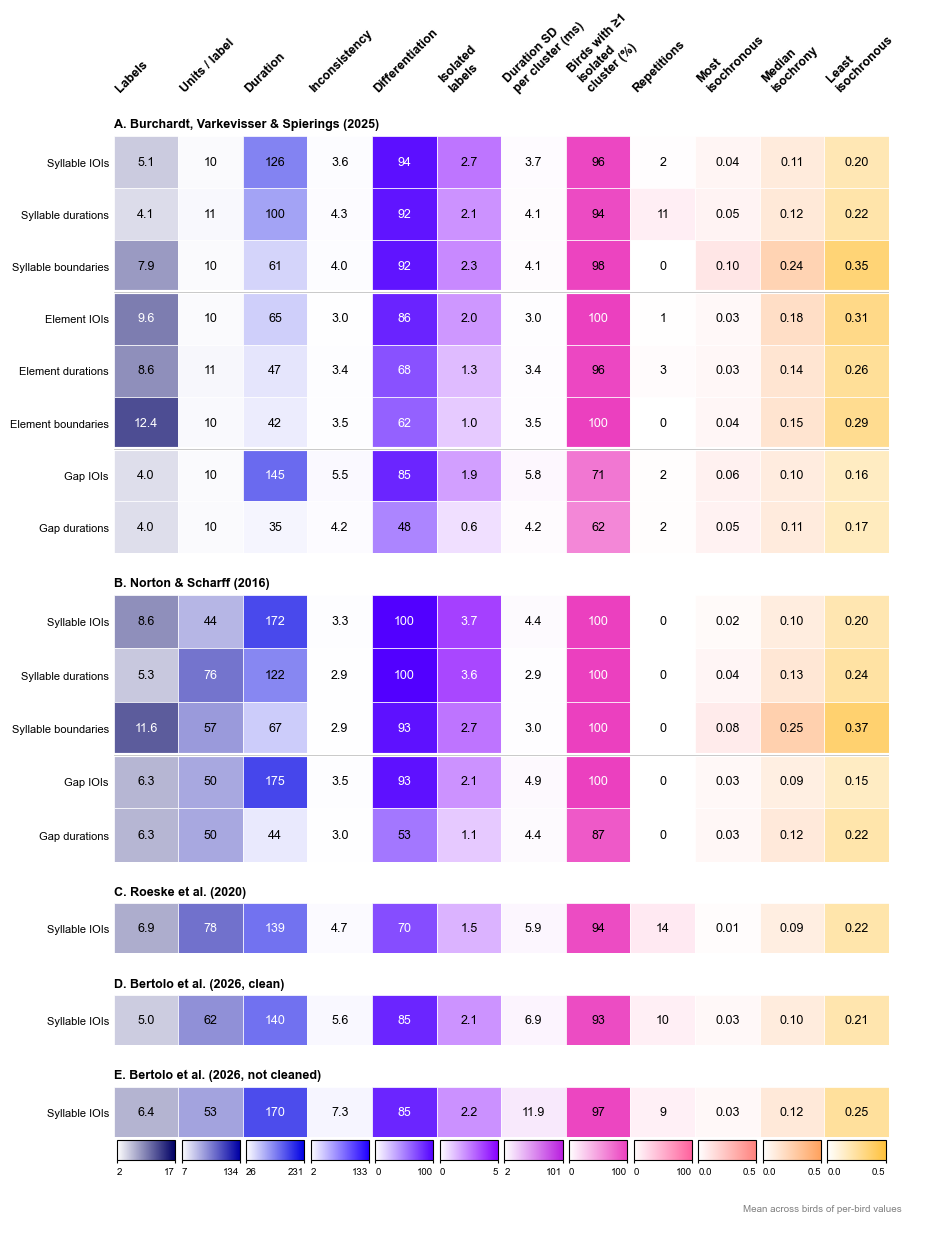

In [18]:
big_suppl_table(metrics, config, exclude_cols=iso_columns)
plt.tight_layout()